# Masterclass ML  : De la donnée à l'IA : construire son premier modèle de Machine Learning

**Le problème métier :** un opérateur mobile perd des clients chaque mois. Recruter un nouveau client coûte bien plus cher que d'en garder un.

**La question :** peut-on prédire, *avant qu'il parte*, quel client risque de résilier (churn) pour lui faire une offre ciblée ?

Les 6 étapes :
1. Charger et comprendre les données
2. Explorer (EDA)
3. Préparer et nettoyer
4. Découper train / test
5. Entraîner un modèle
6. Évaluer, interpréter, utiliser

# Préraration : les outils

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", font_scale=1.3)
pd.set_option('display.max_columns', 20)

# ETAPE 1 : Charger et comprendre les données

In [6]:
df = pd.read_csv("churn_telecom.csv")
print(df.shape)
df.head()

(5025, 12)


,client_id,anciennete_mois,type_forfait,region,conso_data_go,minutes_appels,recharge_mensuelle_fcfa,nb_appels_service_client,utilise_mobile_money,nb_pannes_reseau,jours_sans_recharge,churn
0,C10000,32,prépayé,Dakar,5.8,28,6700.0,2,non,2,87,1
1,C10001,43,prépayé,Dakar,16.4,114,18500.0,2,non,1,0,0
2,C10002,29,postpayé,Touba,7.0,44,4700.0,0,non,1,6,0
3,C10003,26,postpayé,Dakar,7.0,100,2900.0,0,non,3,11,0
4,C10004,47,prépayé,Kaolack,4.9,39,13900.0,1,non,4,7,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   client_id                 5025 non-null   object 
 1   anciennete_mois           5025 non-null   int64  
 2   type_forfait              5025 non-null   object 
 3   region                    5025 non-null   object 
 4   conso_data_go             4844 non-null   float64
 5   minutes_appels            5025 non-null   int64  
 6   recharge_mensuelle_fcfa   5025 non-null   float64
 7   nb_appels_service_client  5025 non-null   int64  
 8   utilise_mobile_money      5025 non-null   object 
 9   nb_pannes_reseau          5025 non-null   int64  
 10  jours_sans_recharge       5025 non-null   int64  
 11  churn                     5025 non-null   int64  
dtypes: float64(2), int64(6), object(4)
memory usage: 471.2+ KB


In [8]:
# la clible : combien de clients sont partis ?
df["churn"].value_counts(normalize=True).round(3)

,proportion
churn,
0,0.838
1,0.162


# ETAPE 2: Explorer les données

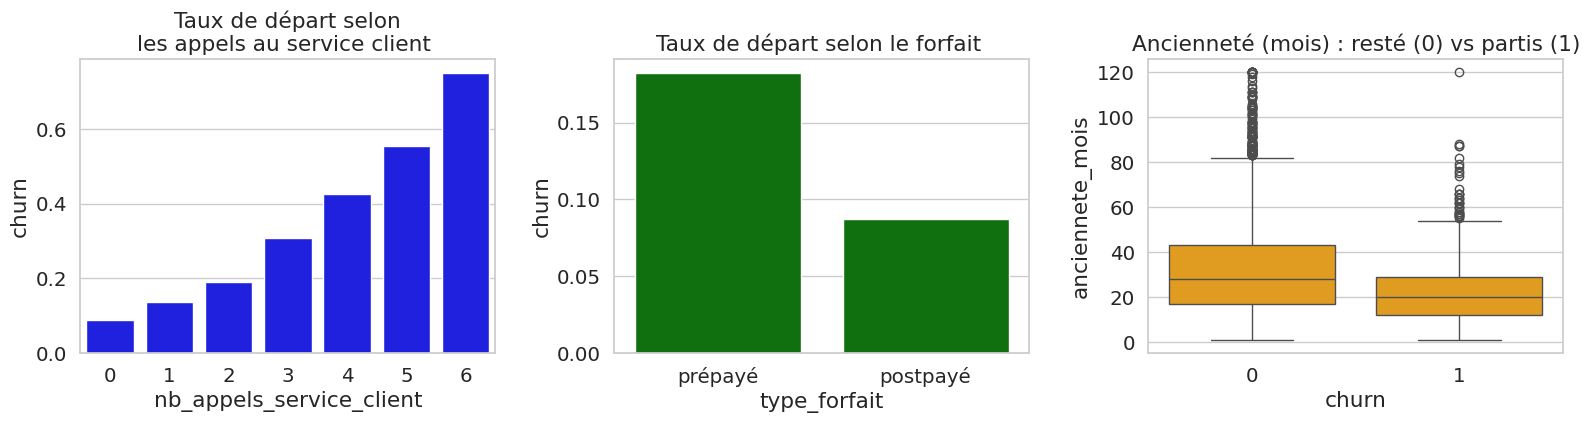

In [10]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4.5))

sns.barplot(data = df, x = "nb_appels_service_client", y="churn", ax=axes[0], errorbar=None, color ="blue")
axes[0].set_title("Taux de départ selon\nles appels au service client ")

sns.barplot(data = df, x = "type_forfait", y="churn", ax=axes[1], errorbar=None, color ="green")
axes[1].set_title("Taux de départ selon le forfait ")

sns.boxplot(data =df, x="churn", y="anciennete_mois", ax=axes[2], color= "orange")
axes[2].set_title("Ancienneté (mois) : resté (0) vs partis (1)")

plt.tight_layout()
plt.show()

# ETAPE 3 : Préparer et Nottoyer

In [11]:
print("Doublons : ", df.duplicated().sum())
print("Valeurs manquantes : \n", df.isna().sum() [df.isna().sum()>0])

Doublons :  25
Valeurs manquantes : 
 conso_data_go    181
dtype: int64


In [13]:
df = df.drop_duplicates()
df = df.drop(columns=["client_id"])  # Un ID n'apprend rien au modele

print(df.shape)

(5000, 11)


In [14]:
# Séparer les variables explicatives (X) de la cible (y)
X = df.drop(columns=["churn"])
y = df["churn"]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numériques : ", num_cols)
print("Catégorielles : ", cat_cols)


Numériques :  ['anciennete_mois', 'conso_data_go', 'minutes_appels', 'recharge_mensuelle_fcfa', 'nb_appels_service_client', 'nb_pannes_reseau', 'jours_sans_recharge']
Catégorielles :  ['type_forfait', 'region', 'utilise_mobile_money']


# ETAPE 4 : Découoper en Train / Test , et le score truqué

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

Train : (4000, 10) (4000,)
Test : (1000, 10) (1000,)


In [16]:
from sklearn.tree import DecisionTreeClassifier
model1 = DecisionTreeClassifier(random_state=42, max_depth=3)
model1.fit(X_train[num_cols], y_train)
print(f"Accuracy sur le test : {model1.score(X_test[num_cols], y_test):.3f}")

Accuracy sur le test : 0.977


In [18]:
# Sur quoi le modele s'appuie lors de l'entrainement ?
Importances = pd.Series(model1.feature_importances_, index=num_cols)
Importances.sort_values(ascending=False).round(2)
print("Importances des variables numériques: ")
display(Importances)

Importances des variables numériques: 


,0
anciennete_mois,0.002903
conso_data_go,0.000000
minutes_appels,0.000000
recharge_mensuelle_fcfa,0.004594
nb_appels_service_client,0.000000
nb_pannes_reseau,0.000000
jours_sans_recharge,0.992503


In [19]:
# On retire  la variable qui triche
for d in (X, X_train, X_test):
    d.drop(columns=["jours_sans_recharge"], inplace=True)

num_cols.remove("jours_sans_recharge")

print("Variables conservés : ", X_train.shape[1])

Variables conservés :  9


In [20]:
# Réentrainement du modele sans la variable "jours_sans_recharge"

model1.fit(X_train[num_cols], y_train)

print(f"Accuracy sur le test : {model1.score(X_test[num_cols], y_test):.3f}")
# Afficher les nouvelles importances des variables
importances = pd.Series(model1.feature_importances_, index=num_cols)
importances.sort_values(ascending=False).round(2)
print(" Nouvelles Importances des variables numériques: ")
display(importances)





Accuracy sur le test : 0.838
 Nouvelles Importances des variables numériques: 


,0
anciennete_mois,0.390052
conso_data_go,0.041101
minutes_appels,0.017070
recharge_mensuelle_fcfa,0.000000
nb_appels_service_client,0.443880
nb_pannes_reseau,0.107897


# ETAPE 5 : Entrainer le vrai modele

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

preprocess = ColumnTransformer([
    ("num", Pipeline ([("imputer", SimpleImputer(strategy ="median")),
                       ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder (handle_unknown="ignore"), cat_cols),
])


model = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

model.fit(X_train, y_train)
print("Model entrainé")
print(f"Accuracy sur le test : {model.score(X_test, y_test):.3f}")

Model entrainé
Accuracy sur le test : 0.683


# ETAPE 6 : Evaluer, interpréter , utiliser

In [25]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Reste", "Part"], digits= 2 ))
print(f"AUC : {roc_auc_score(y_test, y_pred):.3f}")


              precision    recall  f1-score   support

       Reste       0.92      0.68      0.78       839
        Part       0.29      0.68      0.41       161

    accuracy                           0.68      1000
   macro avg       0.60      0.68      0.60      1000
weighted avg       0.82      0.68      0.72      1000

AUC : 0.681


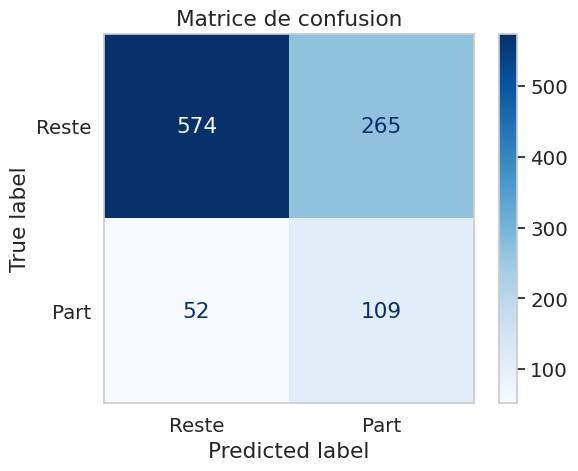

In [26]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Reste", "Part"], cmap="Blues")
plt.title( "Matrice de confusion")
plt.grid(False)
plt.show()

# Utiliser le modele

In [28]:
moussa = pd.DataFrame([{
    "anciennete_mois": 60, "type_forfait": "prépayé", "region": "Dakar",
    "conso_data_go": 0, "minutes_appels": 0, "recharge_mensuelle_fcfa": 0,
    "nb_appels_service_client": 0, "utilise_mobile_money": "non", "nb_pannes_reseau": 0,
}])

risque = model.predict_proba(moussa)[0,1]
print(f"RISQUE DE DEPART DE MOUSSA : {risque:.0%}")

RISQUE DE DEPART DE MOUSSA : 27%


In [29]:
import joblib
joblib.dump(model, "churn_telecom.joblib")
print("modele. sauvegardé")

modele. sauvegardé
